# CNW-Grass gas exchange for developers, 1: `GasExchange` in metafspm

`GasExchange` (`openalea.cnwgrass.metafspm.gas_exchange`) computes each shoot element's photosynthesis (Farquhar),
stomatal conductance (BWB, Leuning, Tuzet or both of the last), surface temperature and transpiration, as a metafspm
component on a plant model's DataStructure. The steps:

0. reading the code: metafspm's component formalism, on `GasExchange`;
1. the equations on one element;
2. the stomatal models, a setting;
3. the corrections;
4. `GasExchange` in a plant model and a scene, its light from Caribu;
5. its transpiration into MECHA's water flow: a translator link.

> **Developer tutorial 1** of three:

> | | notebook | what it covers |
> |---|---|---|
> | 0 | `00_overview.ipynb` | the modules, the original CNW-Grass gas exchange, how the port is validated, the corrections |
> | 1 | `01_gas_exchange_in_metafspm.ipynb` | metafspm's component formalism on `GasExchange` (declarations, steps, forcings, settings), the equations on one element, the stomatal models, the corrections, `GasExchange` in a plant model and a scene with Caribu's light, its transpiration into MECHA |
> | 2 | `02_extend_the_component.ipynb` | add a variable and a step to the component, run it in a scene, test it |
>
> New to the model? Start with the user tutorials (`../user/01_first_run.ipynb`).

In [1]:
import inspect

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openalea.cnwgrass.metafspm import gas_exchange
from openalea.cnwgrass.metafspm.gas_exchange import GasExchange

## 0. Reading the code: metafspm's component formalism

`GasExchange` is a metafspm `FunctionalComponent`. All the ported models are written in this form; this section
presents it on `GasExchange`, so that its code can be read. For more, metafspm's tutorial
`examples/soil_plant_atmosphere/tutorial_fspm2026_general_usage.ipynb` (in the metafspm repository) builds components
step by step; its user guide `docs/user.md` describes each part.

- **A component is a dataclass.** Its fields declare its variables:
  - `input_variable`: written by another model (`by`), read here;
  - `forcing_variable`: a time series given from outside the scene (a meteo table), read by `self.forcing(name)`;
  - `state_variable`: computed by this component;
  - `parameter`: a constant, which may differ between plants;
  - `setting`: a choice for the whole model, one value, never stored per plant.

  Each declaration documents its variable (`unit`, `description`, its bounds and references) and places it at a
  **scale** of the plant graph: most of `GasExchange`'s at the elements' scale, `SubOrgan` (Adel's `StemElement`,
  `LeafElement`); the organs' `diameter` at `Organ`, the canopy height at `Plant`, the apex temperature at `Axis`.
- **Its processes are steps:** methods decorated by their row in the schedule (`@rate`, `@state`, ...). A step's
  arguments are variables, named as declared, each a whole array (one value per entity of its scale, every plant at
  once); a parameter comes per plant. A step returns its output, named after the method, or several as a dict.
- **The values live in the DataStructure**, one array per variable: `ds.get(name)`, `ds.set(name, values)`.

`GasExchange.declarations()` lists what the component declares:

In [2]:
declarations = GasExchange.declarations()
print(declarations["role"].value_counts().to_string())
declarations.loc[declarations["role"].isin(["input", "forcing", "state_variable"]),
                 ["name", "role", "scale", "kind", "unit", "by", "description"]]

role
parameter         58
state_variable    15
input             11
setting           11
forcing            4


,name,role,scale,kind,unit,by,description
0,PARa,input,SubOrgan,intensive,µmol m-2 s-1,CaribuLight,The PAR the element absorbs per unit area
1,green_area,input,SubOrgan,None,m2,ShootArchitecture,The element's green area (0: no gas exchange)
2,height,input,SubOrgan,descriptor,m,ShootArchitecture,The element's height above the soil
3,width,input,SubOrgan,descriptor,m,ShootArchitecture,The lamina element's width (its characteristic...
4,diameter,input,Organ,descriptor,m,ShootArchitecture,The organ's diameter (a stem's or a sheath's c...
5,surfacic_nitrogen,input,SubOrgan,intensive,g m-2,CNMetabolism,The element's surfacic nitrogen Na (non-struct...
6,surfacic_NSC,input,SubOrgan,intensive,µmol m-2,CNMetabolism,The element's surfacic non-structural carbohyd...
7,leaf_water_potential,input,SubOrgan,intensive,MPa,MECHA,The element's leaf water potential (the Tuzet ...
8,SAM_temperature,input,Axis,intensive,°C,Morphogenesis,The axis' apex temperature: the surface temper...
9,PARa_primitives,input,SubOrgan,None,µmol m-2 s-1,CaribuLight,The PAR each primitive of the element absorbs ...


The `kind` says how a variable is aggregated over coarser scales: `transpiration` (mmol s⁻¹) is `extensive`, summed
per organ or plant; the fluxes per unit area (`An`, `Tr`, ...) are `intensive`, weighted by `exchanging_area`, the
area the element exchanges over (the green area it reads: above the soil with `emerged_links`). The optional inputs
(`leaf_water_potential`, `SAM_temperature`, the primitives') take their default when nothing gives them.

The four **forcings** are the weather, the same for every element, read at the end of each step: a scene checks at
its construction that they are given. The **parameters**, per plant, with their units, bounds and references (here the
first ten of 58):

In [3]:
declarations.loc[declarations["role"] == "parameter",
                 ["name", "default", "unit", "min_value", "max_value", "references"]].head(10)

,name,default,unit,min_value,max_value,references
30,Vc_max25_nitrogen_slope,84.965,µmol g-1 s-1,0.0,None,Braune et al. (2009); Evers et al. (2010); Bar...
31,Jmax25_nitrogen_slope,117.6,µmol g-1 s-1,0.0,None,Braune et al. (2009); Evers et al. (2010); Bar...
32,TPU25_nitrogen_slope,9.25,µmol g-1 s-1,0.0,None,Braune et al. (2009); Evers et al. (2010); Bar...
33,Rdark25_nitrogen_slope,0.493,µmol g-1 s-1,0.0,None,Braune et al. (2009); Evers et al. (2010); Bar...
34,electron_yield_nitrogen_slope,0.0413,m2 g-1,0.0,None,Braune et al. (2009); Evers et al. (2010); Bar...
35,Vc_max25_nitrogen_minimum,0.0,g m-2,0.0,None,Braune et al. (2009); Evers et al. (2010); Bar...
36,Jmax25_nitrogen_minimum,0.0,g m-2,0.0,None,Braune et al. (2009); Evers et al. (2010); Bar...
37,TPU25_nitrogen_minimum,0.0,g m-2,0.0,None,Braune et al. (2009); Evers et al. (2010); Bar...
38,Rdark25_nitrogen_minimum,0.0,g m-2,0.0,None,Braune et al. (2009); Evers et al. (2010); Bar...
39,electron_yield_intercept,0.2184,mol mol-1,0.0,None,Braune et al. (2009); Evers et al. (2010); Bar...


The **settings**: the stomatal model, whether the carbohydrates inhibit photosynthesis, the primitive scale, the
fixed point's numerics, the wind's reference height, the labels telling the elements apart, and the corrections:

In [4]:
declarations.loc[declarations["role"] == "setting", ["name", "default", "description"]]

,name,default,description
88,stomatal_model,BWB,"The stomatal conductance: 'BWB' (Ball, Woodrow..."
89,NSC_retroinhibition,True,"Ag inhibited by the NSC (min(Ac, Aj)), else mi..."
90,primitive_scale,False,The photosynthesis of each primitive of the el...
91,convergence_tolerance,0.01,The relative change of Ci and Ts that ends the...
92,maximum_iterations,30,The fixed point's iterations at most
93,reference_height,2,The height of the wind's measurement above the...
94,minimum_wind_speed,0.1,The smallest wind speed used
95,lamina_labels,"(Blade,)",The organs' labels of the laminae (a horizonta...
96,exchanging_labels,"(StemElement, LeafElement, LeafElement1)",The labels of the elements that exchange gas
97,hidden_labels,"(HiddenElement,)",The labels of the elements inside the sheaths'...


Three steps follow the physics: `_canopy_height` (each plant's canopy height: its exchanging elements' highest),
`_capacities` (each element's photosynthetic capacities at 25 °C, linear in its surfacic nitrogen), both in the row
"rate", then `_exchange` in the row "state": each element's fixed point of the photosynthesis, the stomatal
conductance, the internal CO₂ and the energy balance (the function `element_exchange`, called element by element).
`include_inactive=True` computes every element, not only the growing ones.

In [5]:
for stages, steps in GasExchange.schedule():
    print(f"{', '.join(stages):>6}  {', '.join(steps)}")
print()
print(inspect.getsource(GasExchange._capacities))
print(inspect.getdoc(GasExchange._exchange))

  rate  _canopy_height, _capacities
 state  _exchange

    @rate(include_inactive=True)
    def _capacities(self, surfacic_nitrogen, Vc_max25_nitrogen_slope, Jmax25_nitrogen_slope, TPU25_nitrogen_slope,
                    Rdark25_nitrogen_slope, electron_yield_nitrogen_slope, Vc_max25_nitrogen_minimum,
                    Jmax25_nitrogen_minimum, TPU25_nitrogen_minimum, Rdark25_nitrogen_minimum,
                    electron_yield_intercept) -> dict:
        """The photosynthetic capacities at 25 °C, linear in the surfacic nitrogen."""
        nitrogen = np.asarray(surfacic_nitrogen, dtype=float)
        return {"Vc_max25": Vc_max25_nitrogen_slope * (nitrogen - Vc_max25_nitrogen_minimum),
                "Jmax25": Jmax25_nitrogen_slope * (nitrogen - Jmax25_nitrogen_minimum),
                "TPU25": TPU25_nitrogen_slope * (nitrogen - TPU25_nitrogen_minimum),
                "Rdark25": Rdark25_nitrogen_slope * (nitrogen - Rdark25_nitrogen_minimum),
                "electron_yield": elec

## 1. The equations on one element

Under the component, the equations are plain functions of one element (the module's docstring writes them all).
`element_exchange` iterates on the internal CO₂ `Ci` and the surface temperature `Ts` until both change by less than
1 %, at most 30 times. Its arguments: the element's PAR, nitrogen, carbohydrates, capacities, characteristic
dimension (a blade's width), height, its canopy's height, whether it is a lamina, its water potential, the starting
`Ci` and `Ts`, the weather, the parameters (`default_parameters()`) and the options (the settings). A blade's light
response:

In [6]:
parameters = gas_exchange.default_parameters()
capacities_25 = gas_exchange.default_capacities()
nitrogen = 2.
capacities = tuple(capacities_25[f"{name}_nitrogen_slope"] * (nitrogen - capacities_25[f"{name}_nitrogen_minimum"])
                   for name in ("Vc_max25", "Jmax25", "TPU25", "Rdark25")) + (
    capacities_25["electron_yield_nitrogen_slope"] * nitrogen + capacities_25["electron_yield_intercept"],)
weather = gas_exchange.Weather(air_temperature=20., ambient_CO2=410., relative_humidity=0.6, wind_speed=2.)
recommended = gas_exchange.CORRECTIONS.resolve("recommended")


def blade(PAR, model="BWB", corrections=recommended, leaf_water_potential=-0.1, weather=weather):
    options = gas_exchange.Options(model, True, 0.01, 30, 2., 0.1, corrections)
    Ag, An, Rd, gs, Ci, Ts, Tr, converged = gas_exchange.element_exchange(
        PAR, nitrogen, 0., capacities, 0.015, 0.3, 0.4, True, leaf_water_potential, weather.ambient_CO2,
        weather.air_temperature, weather, parameters, options)
    return dict(PAR=PAR, An=An, gs=gs, Ci=Ci, Ts=Ts, Tr=Tr, converged=converged)


light = pd.DataFrame([blade(PAR) for PAR in (0., 50., 200., 500., 1000., 1500., 2000.)])
light.round(3)

,PAR,An,gs,Ci,Ts,Tr,converged
0,0.0,0.000,0.050,410.000,18.974,0.407,True
1,50.0,2.632,0.093,363.582,19.170,0.729,True
2,200.0,10.038,0.203,326.811,20.069,1.572,True
3,500.0,20.290,0.359,311.509,22.217,3.120,True
4,1000.0,29.552,0.503,304.355,25.798,5.699,True
5,1500.0,33.575,0.567,302.062,29.173,8.360,True
6,2000.0,33.211,0.562,302.525,32.458,11.057,True


A 1.5 cm wide blade at 30 cm in a 40 cm canopy, with 2 g m⁻² of nitrogen. In the dark `An` is 0 (the model returns
no assimilation when `Ag` ≤ 0) and `gs` is its minimum, `g0`; with light, `An` saturates, the stomata open, `Ci`
falls and the blade warms.

## 2. The stomatal models, a setting

The stomatal model is the setting `stomatal_model`: one value for the component, checked against its choices at its
construction (a scenario sets it as a parameter, `{"stomatal_model": "Leuning"}`, but for every plant at once).

In [7]:
try:
    GasExchange(stomatal_model="Jarvis")
except ValueError as error:
    print(error)

GasExchange.stomatal_model: one of ['BWB', 'Leuning', 'Tuzet', 'hydraulics'], got 'Jarvis'


The four models on the same blade: BWB from `Ag`, the humidity and the surface CO₂; Leuning from the vapour pressure
deficit; Tuzet from the leaf water potential; hydraulics both. Their conductance against the light, and Tuzet's against
the water potential:

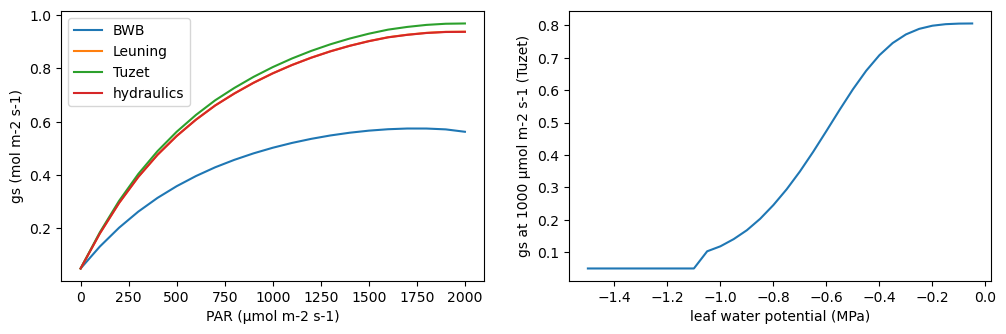

In [8]:
PARs = np.linspace(0., 2000., 21)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for model in gas_exchange.STOMATAL_MODELS:
    axes[0].plot(PARs, [blade(PAR, model)["gs"] for PAR in PARs], label=model)
axes[0].set_xlabel("PAR (µmol m-2 s-1)"); axes[0].set_ylabel("gs (mol m-2 s-1)"); axes[0].legend()
potentials = np.linspace(-1.5, -0.05, 30)
axes[1].plot(potentials, [blade(1000., "Tuzet", leaf_water_potential=potential)["gs"] for potential in potentials])
axes[1].set_xlabel("leaf water potential (MPa)"); axes[1].set_ylabel("gs at 1000 µmol m-2 s-1 (Tuzet)");

## 3. The corrections

The legacy's behaviours found to be errors are corrected by name (`CORRECTIONS`), all by default (`"recommended"`);
`corrections=()` reproduces the legacy bit for bit (`test/test_gas_exchange.py`). The compensation point Γ of the
Leuning, Tuzet and hydraulics models, legacy and corrected, at 20 °C (µmol mol⁻¹):

In [9]:
print(f"legacy: {gas_exchange.compensation_point(20., parameters, False):.4f}, "
      f"corrected: {gas_exchange.compensation_point(20., parameters, True):.2f}")
rows = {name: blade(1000., "Leuning", corrections=chosen) for name, chosen in (("legacy", frozenset()),
                                                                              ("corrected", recommended))}
pd.DataFrame(rows).T[["An", "gs", "Ci", "Ts", "Tr"]].round(4)

legacy: 0.0017, corrected: 27.93


,An,gs,Ci,Ts,Tr
legacy,30.273465,0.7296,331.760889,24.785226,6.100263
corrected,30.317904,0.781832,336.087879,24.630215,6.161671


The legacy's Γ, about 0.002 µmol mol⁻¹, leaves `Cs − Γ` larger and the Leuning conductance smaller. The other two:
`vapour_pressure_slope` (the slope of the saturation vapour pressure, at the fixed point's first iteration: the
legacy's about four times too small) moves the fixed point within its tolerance; `primitive_aggregation` concerns the
primitive scale (`primitive_scale=True`, each element's primitives lit separately). Fixed without a name, since the
legacy fails there: a previous `Ci` of 0, an air at 0 °C, a canopy height of 0, a stem of null diameter.

## 4. `GasExchange` in a plant model, its light from Caribu

A plant model (a metafspm `CompositeModel`) builds its components on the plant's DataStructure and couples them. The
users' `ExchangingWheat` (`openalea.cnwgrass.metafspm.simulation`) is Adel's wheat shoot (its architecture grown by a
development scenario), Caribu's optics and `GasExchange`:

In [10]:
from openalea.cnwgrass.metafspm import simulation

print(inspect.getsource(simulation.ExchangingWheat))

class ExchangingWheat(ScenarioShoot):
    """The plant model: Adel's wheat shoot (ShootArchitecture grown by ScenarioDevelopment), its elements' optics
    (Caribu's PlantOptics, which the light reads) and their gas exchange (GasExchange: its PARa the light's, by name;
    its elements' height from Adel's z1, z2, adel_links). A subclass may compute the gas exchange with a subclass of
    GasExchange (gas_exchange_component), its links named after it (translator, adel_links(receiver=...))."""
    gas_exchange_component = GasExchange
    translator = adel_links()

    def __init__(self, data_structure, time_step):
        self.architecture = ShootArchitecture(data_structure=data_structure, time_step=time_step)
        self.development = ScenarioDevelopment(data_structure=data_structure, time_step=time_step)
        self.optics = PlantOptics(data_structure=data_structure, time_step=time_step)
        self.gas_exchange = self.gas_exchange_component(data_structure=data_structure, time_step=

`couple(..., translator=)` links what the components share. Most of `GasExchange`'s inputs are Adel's variables of
the same name (`green_area`, `width`, `diameter`), shared on the DataStructure. Adel has no element height:
`adel_links()` links it by a formula of Adel's `z1`, `z2` (`element_height`, their mean). A plant whose shoot
crosses the soil surface (its crown below it) links `emerged_links()` instead: each element's height and green area
of its part above the Scene's soil surface (from Adel's triangles, as Caribu's light is cut at the soil), the green
area under a receiver-private name (metafspm's `Link(names=)`): the gas exchange reads it as its `green_area` and
exchanges over it (`exchanging_area`), Adel's `green_area` staying the whole element's. Here the stand is above
the soil:

In [11]:
for link in gas_exchange.adel_links().links:
    print(f"{link.receiver}.{link.variable} <- {link.provider} {link.sources}, {link.formula.__name__}")

GasExchange.height <- ShootArchitecture ('z1', 'z2'), element_height


The light is the scene's: an **environment model** (`CaribuLightModel`) lights the union of the plants' elements. A
scene by hand: a planting table (Adel's sown stand, its plants' development delays, the stand's size, the infinite
canopy's pattern), the scene with the light, the weather as forcings (constants here) and its calendar (the sun's
place). The plants are first grown to 600 °Cd (their development's `start`, by one call: `ExchangingWheat.grow`), then the
scene runs one hour, from 11 to
12 h UT:

In [12]:
from openalea.adel.development import random_delays, sown_stand
from openalea.adel.leaf_shapes import LeafShapes
from openalea.caribu.component import CaribuLightModel
from openalea.metafspm.scene.population import planting
from openalea.metafspm.scene.scene import Scene

shoot = {"n_sect": 2, "leaves": LeafShapes.echap(xy_model="Soissons_byleafclass"), "start": 600.}
table = planting(sown_stand(8, n_rows=2), simulation.ExchangingWheat, shoot,
                 [{"delay": float(delay)} for delay in random_delays(8)], xrange=0.16, yrange=0.3)
weather = {"PARi": 1500., "air_temperature": 20., "relative_humidity": 0.6, "ambient_CO2": 410., "wind_speed": 2.}
scene = Scene(table, environment=[CaribuLightModel], environment_scenarios=[{"sun": True}], time_step=3600.,
              forcings=weather, start=(130, 11.))
plant_model = scene.populations[0].instance
plant_model.grow()
scene.run()
ds = scene.populations[0].data_structure
print(f"{len(ds.entity_ids('Plant'))} plants, {ds.n_nodes()} elements, "
      f"{np.sum(np.asarray(ds.get('An')) * np.asarray(ds.get('exchanging_area'))):.3f} µmol CO2 s-1 fixed")

8 plants, 1176 elements, 0.487 µmol CO2 s-1 fixed


The scene links the light's outputs to the plant models' inputs of the same name, and the plant models' states to
the light's inputs of the same name: the default **identity links** (`scene.translator.links`). `GasExchange.PARa` is
Caribu's `PARa`; Caribu reads the plants' optics:

In [13]:
for link in scene.translator.links:
    print(f"{link.receiver}.{link.variable} <- {link.provider}.{', '.join(link.sources)} ({link.detail})")
light = scene.environment[0].light.data_structure
np.testing.assert_array_equal(np.asarray(ds.get("PARa")), np.asarray(light.get("PARa")))     # one population

CaribuLight.PAR_reflectance <- PlantOptics.PAR_reflectance (identity)
CaribuLight.PAR_transmittance <- PlantOptics.PAR_transmittance (identity)
GasExchange.PARa <- CaribuLight.PARa (identity)


The scene runs the environment models, then the plant models, each after the exchanges into it: at each step the
light lights the canopy as the plants were at the end of the step before, and the gas exchange reads this step's
`PARa`. A step reads its forcings
over its hour (their means): the weather of 11 to 12 h here.

## 5. Its transpiration into MECHA's water flow

MECHA (`openalea.mecha`) computes the water flow through a plant's tissues. Its `MechaHydraulics` reads each
transpiring organ's `leaf_transpiration`:

In [14]:
from openalea.mecha.component import MechaHydraulics

MechaHydraulics.declarations().set_index("name").loc[["leaf_transpiration"], ["role", "scale", "kind", "unit", "by"]]

,role,scale,kind,unit,by
name,,,,,
leaf_transpiration,input,Organ,extensive,cm3 d-1,Transpiration


`GasExchange.transpiration` is per element (`SubOrgan`), in mmol of water s⁻¹, extensive. A translator link gives it
to MECHA: summed per organ (the extensive kind's mapping to the coarser scale), times the unit factor from mmol s⁻¹
to cm³ d⁻¹, 18 × 10⁻³ cm³ mmol⁻¹ (1 g of water is 1 cm³) × 86400 s d⁻¹ = 1555.2. An amount into a volume is not a
unit conversion metafspm checks (`unit_check=False`: a deliberate factor, the water's molar volume).

Running MECHA on Adel's shoot needs its anatomy model (GRANAP) and a root system, beyond this tutorial: a stand-in
receives the link here, declaring `leaf_transpiration` as `MechaHydraulics` does.

In [15]:
from dataclasses import dataclass

from openalea.metafspm.coupling.component import FunctionalComponent, input_variable
from openalea.metafspm.data_structure.configs import ScalesConfig

WATER_FACTOR = 18e-3 * 86400                     # mmol s-1 of water into cm3 d-1


@dataclass
class OrganWater(FunctionalComponent):
    """A stand-in for MechaHydraulics' input: each organ's transpiration."""
    leaf_transpiration: float = input_variable(unit="cm3 d-1", description="an organ's transpiration",
                                               by="Transpiration", default=0., scale=ScalesConfig.Organ,
                                               kind="extensive")


class WheatWithWater(simulation.ExchangingWheat):
    translator = gas_exchange.adel_links().link("OrganWater", "leaf_transpiration", "GasExchange",
                                                {"transpiration": WATER_FACTOR}, unit_check=False)

    def __init__(self, data_structure, time_step):
        super().__init__(data_structure, time_step)
        self.water = OrganWater(data_structure=data_structure, time_step=time_step)
        self.couple(self.development, self.architecture, self.optics, self.gas_exchange, self.water,
                    translator=self.translator)

    def run(self):
        super().run()
        self.water()


table = planting(sown_stand(8, n_rows=2), WheatWithWater, shoot,
                 [{"delay": float(delay)} for delay in random_delays(8)], xrange=0.16, yrange=0.3)
scene = Scene(table, environment=[CaribuLightModel], environment_scenarios=[{"sun": True}], time_step=3600.,
              forcings=weather, start=(130, 11.))
scene.populations[0].instance.grow()
scene.run()
ds = scene.populations[0].data_structure
per_organ = ds.map_to(np.asarray(ds.get("transpiration")), "node", "Organ", "sum")
np.testing.assert_allclose(np.asarray(ds.get("leaf_transpiration")), WATER_FACTOR * per_organ, rtol=1e-12)
print(f"{len(per_organ)} organs receive {np.sum(ds.get('leaf_transpiration')):.2f} cm3 d-1 in all, "
      f"the elements' {np.sum(ds.get('transpiration')):.5f} mmol s-1 times {WATER_FACTOR:g}")

504 organs receive 132.20 cm3 d-1 in all, the elements' 0.08500 mmol s-1 times 1555.2


In a plant model with `MechaHydraulics`, the link's receiver is `MechaHydraulics`. The feedback the other way, the leaf
water potential that the Tuzet and hydraulics models read (`leaf_water_potential`, MPa, per element), comes from
MECHA's `water_potential` (hPa, at its compartments), a name of its own since the units differ: `mecha_links()`
links it, a factor 1e-4 and the mean over each element's compartments weighted by MECHA's `liquid_volume` (the air
spaces and pores, at the air's Kelvin equivalent, left out), at the step before: a lagged feedback, outside MECHA's
solve. The plant model registers `leaf_water_potential` at the elements (`SubOrgan`) before coupling: an optional
input is not registered until something gives it. It is not run here (`test/test_mecha_links.py` runs it on
GRANAP's anatomies); the link:

In [16]:
for link in gas_exchange.mecha_links().links:
    print(f"{link.receiver}.{link.variable} <- {link.provider} {link.sources}, {link.aggregation} by {link.weight}")

GasExchange.leaf_water_potential <- MechaHydraulics {'water_potential': 0.0001}, weighted_mean by liquid_volume


The documentation's page `doc/metafspm/gas_exchange.rst` lists the equations, the declarations and the legacy's
behaviours with what the port does.